### Lab Assignment - 7 
#### Image Representation, PCA, Eigenfaces and Face Recognition

##### Part A - Image Representation 

X: (400, 10304) y: (400,)
pixel range: 0.0 to 251.0
train: (320, 10304) test: (80, 10304)


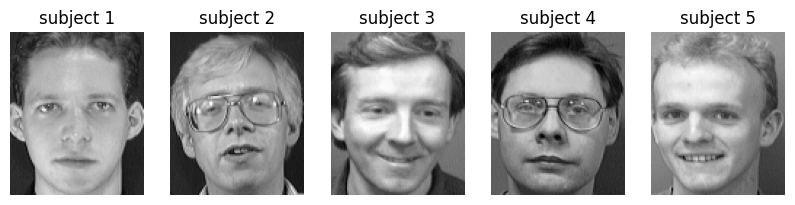

In [3]:
import numpy as np
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

DATA_DIR = Path("data")   
H, W = 112, 92

def load_orl(data_dir: Path):
    X, y = [], []
    for subj in range(1, 41):
        for img_id in range(1, 11):
            img = Image.open(data_dir / f"s{subj}" / f"{img_id}.pgm")
            arr = np.asarray(img, dtype=np.float64)       # (112, 92) pixel matrix
            X.append(arr.flatten())                        # (10304,) feature vector
            y.append(subj)
    return np.array(X), np.array(y)

X, y = load_orl(DATA_DIR)
print("X:", X.shape, "y:", y.shape)                        # expect (400, 10304) (400,)
print("pixel range:", X.min(), "to", X.max())

def stratified_split(y, n_train=8, seed=42):
    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for s in np.unique(y):
        idx = rng.permutation(np.where(y == s)[0])
        train_idx += idx[:n_train].tolist()
        test_idx += idx[n_train:].tolist()
    return np.array(train_idx), np.array(test_idx)

tr, te = stratified_split(y)
X_train, y_train = X[tr], y[tr]
X_test, y_test = X[te], y[te]
print("train:", X_train.shape, "test:", X_test.shape)     # (320, 10304) (80, 10304)

# sanity: every subject appears in both sets
assert set(y_train) == set(y_test) == set(range(1, 41))

fig, ax = plt.subplots(1, 5, figsize=(10, 3))
for a, i in zip(ax, [0, 10, 20, 30, 40]):
    a.imshow(X[i].reshape(H, W), cmap="gray"); a.axis("off"); a.set_title(f"subject {y[i]}")
plt.show()

##### Part B - PCA, Eigenfaces and Compression

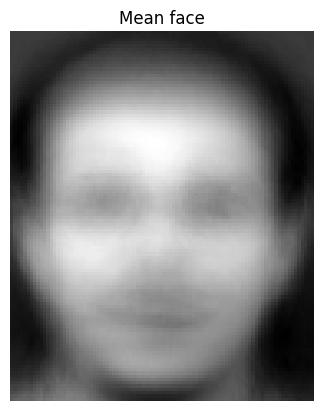

components kept (eig): 319
eigenvalues match: True
min |cos| over top 100 components: 0.9999999999999964
top 5 eigenvalues (eig): [2837009.98929293 2013339.00426591 1131088.32713936  899267.53112397
  794485.75315848]
top 5 eigenvalues (svd): [2837009.98929294 2013339.00426591 1131088.32713936  899267.53112397
  794485.75315848]


In [4]:
# --- Mean face and centering ---
mean_face = X_train.mean(axis=0)            # (10304,)
Xc = X_train - mean_face                    # (320, 10304)
n = Xc.shape[0]

plt.imshow(mean_face.reshape(H, W), cmap="gray")
plt.title("Mean face"); plt.axis("off"); plt.show()

# --- Method 1: eigendecomposition (via the small n x n matrix) ---
G = (Xc @ Xc.T) / (n - 1)                   # (320, 320)
eigvals, eigvecs = np.linalg.eigh(G)        # ascending order
order = np.argsort(eigvals)[::-1]           # sort descending
eigvals, eigvecs = eigvals[order], eigvecs[:, order]

keep = eigvals > 1e-10 * eigvals[0]         # drop the ~0 eigenvalue(s)
eigvals, eigvecs = eigvals[keep], eigvecs[:, keep]
r = len(eigvals)

comp_eig = Xc.T @ eigvecs                   # (10304, r) map back to pixel space
comp_eig /= np.linalg.norm(comp_eig, axis=0)
comp_eig = comp_eig.T                       # (r, 10304), one eigenface per row

# --- Method 2: SVD ---
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
eigvals_svd = S**2 / (n - 1)
comp_svd = Vt                               # (320, 10304)

# --- Compare the two ---
print("components kept (eig):", r)
print("eigenvalues match:", np.allclose(eigvals, eigvals_svd[:r]))
cos = np.abs(np.sum(comp_eig[:100] * comp_svd[:100], axis=1))
print("min |cos| over top 100 components:", cos.min())   # should be ~1.0
print("top 5 eigenvalues (eig):", eigvals[:5])
print("top 5 eigenvalues (svd):", eigvals_svd[:5])